# Referencias

1. [Tesis de grado — referencia del material original](https://drive.google.com/file/d/1fxbhCJ6f9nTZXvzaqboVLrMFQE1AlXZv/view?usp=share_link).
2. [Dive into Deep Learning](https://d2l.ai/).
3. [PyTorch: Tensor Views](https://docs.pytorch.org/docs/stable/tensor_view.html).
4. [PyTorch: Tensor.view](https://docs.pytorch.org/docs/stable/generated/torch.Tensor.view.html).
5. [PyTorch: Broadcasting semantics](https://docs.pytorch.org/docs/stable/notes/broadcasting.html).
6. [PyTorch: Storage](https://docs.pytorch.org/docs/stable/storage.html).
7. [PyTorch: torch.matmul](https://docs.pytorch.org/docs/stable/generated/torch.matmul.html).

Los ejemplos de esta edición se verificaron en **PyTorch 2.15.0+cpu**, con tensores densos y `layout=torch.strided`. Los detalles internos pueden variar entre versiones.

# 1. Cimientos y runtime de PyTorch

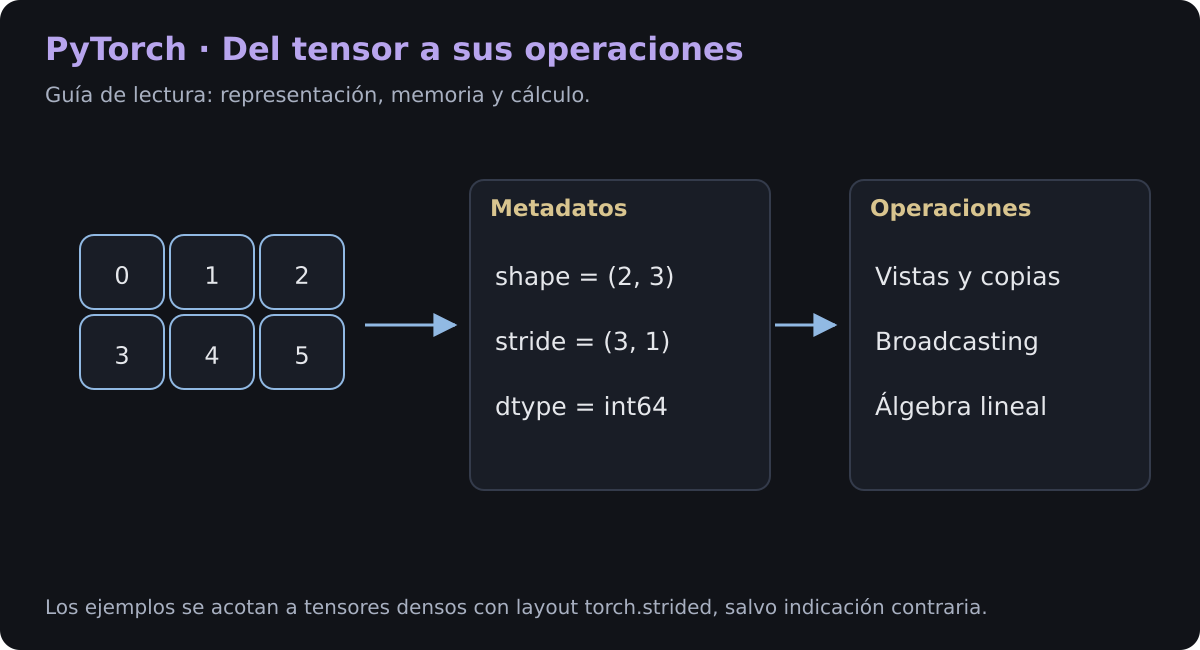

*Fig. 1.1. Cimientos de PyTorch: metadatos, datos y operaciones.*

## 1.1. Anatomía de un tensor (`torch.Tensor`)

Un tensor representa valores con una **forma**, un **tipo de dato**, un **dispositivo** y un **layout**. En los tensores densos `strided` de esta guía, un descriptor indica cómo recorrer un almacenamiento mediante tamaños, strides y un offset inicial.

PyTorch añade operaciones aceleradas en distintos dispositivos y diferenciación automática. El registro de gradientes requiere condiciones como `requires_grad=True`, un modo con gradientes habilitados y operaciones diferenciables; **no se rastrea cualquier operación sobre cualquier tensor**.

Una GPU puede acelerar determinados cálculos, pero la ventaja depende del tamaño, las transferencias y el tipo de operación. Para ejemplos pequeños, CPU suele ser suficiente.

**Analogía:** el almacenamiento es una fila de casilleros; el tensor aporta el plano para leerlos. Dos planos pueden describir formas diferentes sin duplicar los casilleros. Esta separación es similar a las vistas de NumPy.

El plano no obliga a que el recorrido lógico sea consecutivo: una transposición, un recorte o una expansión pueden reutilizar datos con strides distintos.

En C++, `at::Tensor` es un handle que referencia una implementación. `c10::TensorImpl` conserva metadatos y estado; para el caso denso considerado, un `c10::Storage` referencia un `c10::StorageImpl` que administra el bloque de datos. El objeto `torch.Tensor` de Python añade su propia envoltura.

La página [Arquitectura de tensores en C++](clase-02-arquitectura-c10-aten.html) profundiza en esas responsabilidades.

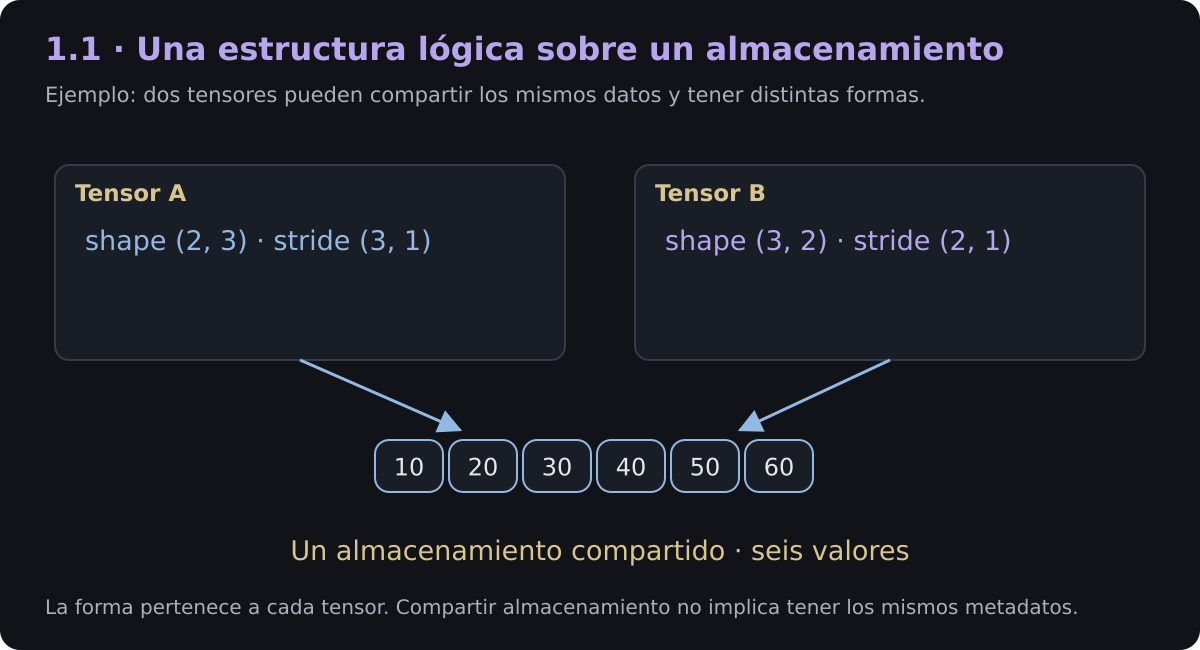

*Fig. 1.2. Dos descriptores pueden interpretar el mismo almacenamiento.*

# 2. Operaciones con tensores

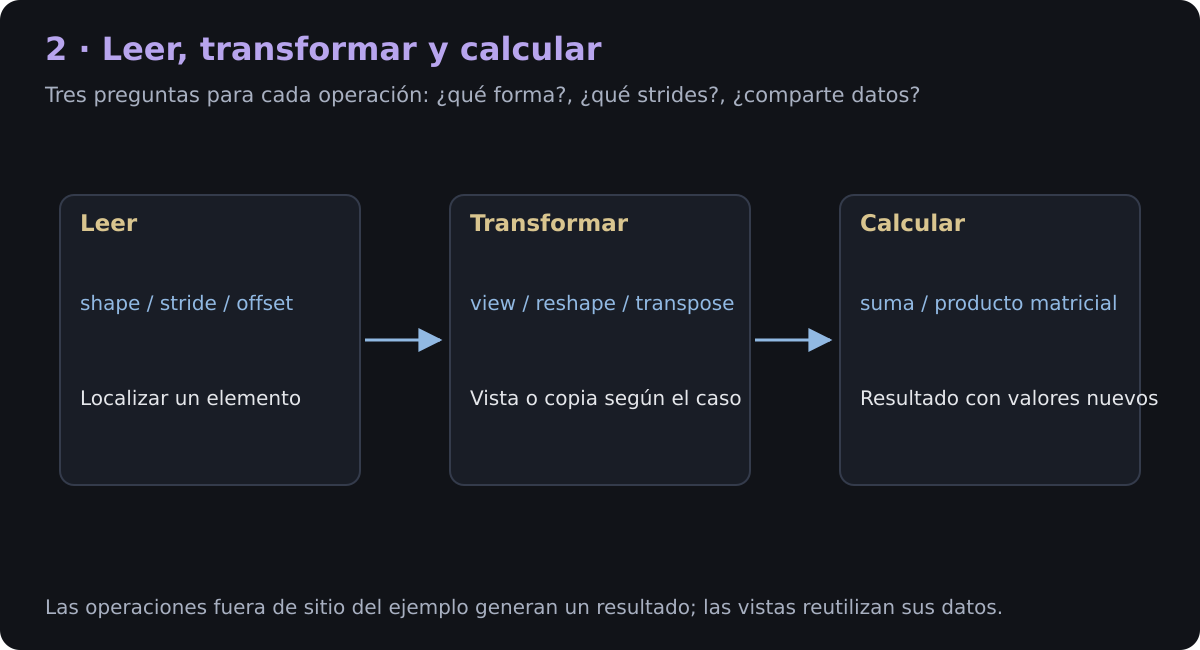

*Fig. 1.3. Tres preguntas para observar el efecto de una operación.*

## 2.1. Atributos fundamentales

| Atributo | Qué informa | Ejemplo |
| :--- | :--- | :--- |
| `shape` / `size()` | Longitud de cada eje | `(2, 3)` |
| `ndim` | Cantidad de ejes | `2` |
| `dtype` | Representación de cada elemento | `torch.float32` |
| `device` | Dispositivo asociado | `cpu`, `cuda:0` |
| `layout` | Organización general | `torch.strided` |

`device` también existe en tensores especiales, como `meta`, que no tienen un bloque de datos materializado. Aquí trabajaremos con CPU y layout denso.

In [1]:
# Importar PyTorch para trabajar con tensores.
import torch

# Fijar explícitamente el dtype del ejemplo.
x = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]], dtype=torch.float32)
# Mostrar la forma y la cantidad de ejes.
print("Forma:", tuple(x.shape), "| ndim:", x.ndim)
# Mostrar el tipo, el dispositivo y el layout.
print("dtype:", x.dtype, "| device:", x.device, "| layout:", x.layout)
# Mostrar los valores del tensor.
print(x)


Forma: (2, 3) | ndim: 2
dtype: torch.float32 | device: cpu | layout: torch.strided
tensor([[1., 2., 3.],
        [4., 5., 6.]])


### 2.1.1. Sizes, strides y almacenamiento

El almacenamiento de un tensor denso representa un bloque de bytes. Sus metadatos describen cuántos elementos hay en cada eje y cuántas **posiciones de elemento** se avanza al incrementar un índice.

Un stride no se expresa directamente en bytes. Para convertirlo a bytes hay que multiplicarlo por `element_size()`. Los punteros que observamos desde Python son direcciones del espacio de direcciones del proceso o del dispositivo; **no son direcciones físicas de RAM**.

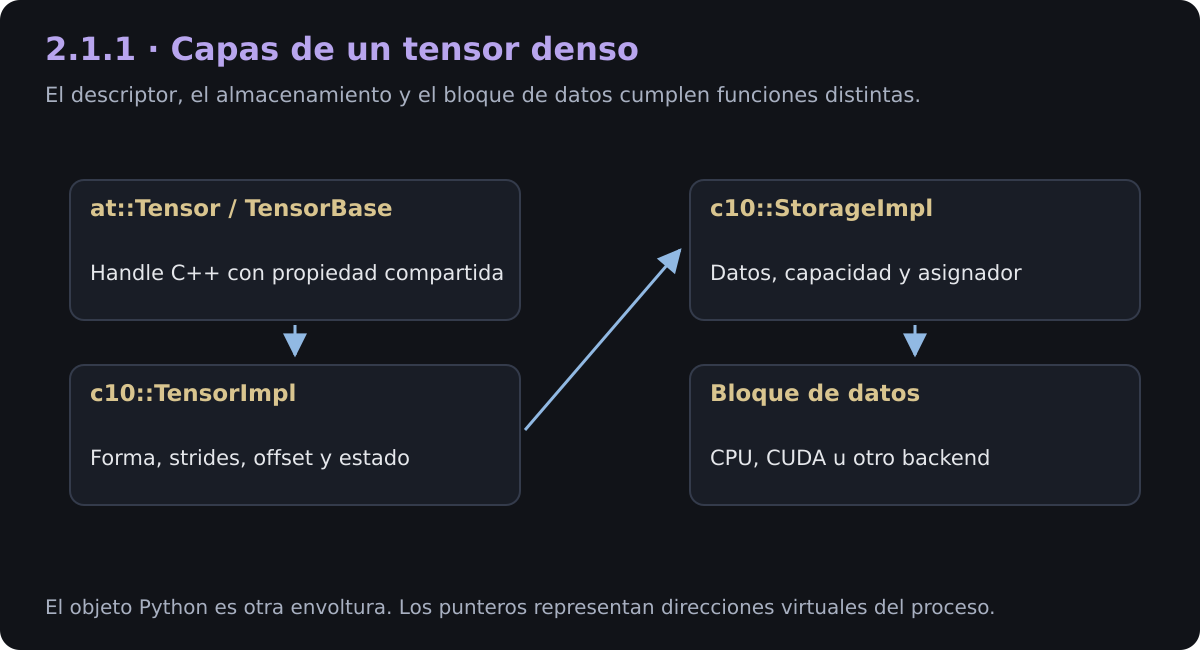

*Fig. 1.4. Responsabilidades del handle, TensorImpl, StorageImpl y los datos.*

### 2.1.2. La ecuación de direccionamiento

Para un tensor denso `strided`, el offset del elemento de índices $(i_0,\dots,i_{N-1})$ respecto al inicio del almacenamiento es:

$$o=\operatorname{storage\_offset}+\sum_{k=0}^{N-1} i_k\operatorname{stride}_k.$$

La dirección de byte correspondiente es:

$$p_{\mathrm{elemento}}=p_{\mathrm{storage}}+o\cdot\operatorname{element\_size}.$$

`tensor.data_ptr()` ya apunta al primer elemento de esa vista. Por tanto, si se parte de ese puntero, **no se suma de nuevo `storage_offset()`**.

En `[[10,20,30],[40,50,60]]`, con strides `(3,1)` y offset 0, el elemento `[1,2]` ocupa la posición 5 del almacenamiento. Si el dtype es `float32`, su desplazamiento desde la base es 20 bytes.

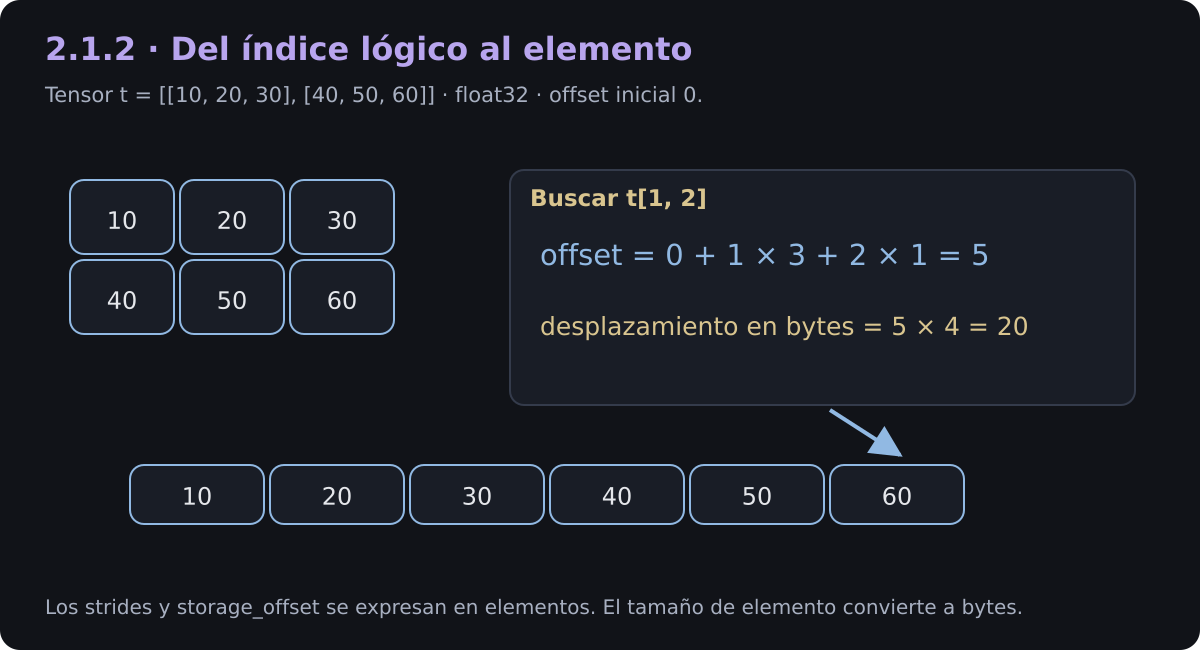

*Fig. 1.5. Cálculo del offset de elemento y su conversión a bytes.*

In [2]:
# Importar las operaciones de tensores, decodificación binaria y datos del host.
import torch
import struct
import sys

# Crear seis valores float32 contiguos en CPU.
t = torch.tensor([[10.0, 20.0, 30.0], [40.0, 50.0, 60.0]], dtype=torch.float32)
# Obtener el almacenamiento completo de este ejemplo pequeño.
storage = t.untyped_storage()
# Convertir sus bytes a un objeto inmutable de Python.
bytes_raw = bytes(storage)
# Obtener el tamaño en bytes de cada elemento.
bytes_per_elem = t.element_size()
# Usar la base del almacenamiento para no contar dos veces el offset inicial.
base_ptr = storage.data_ptr()
# Informar las propiedades que intervienen en el direccionamiento.
print("shape:", tuple(t.shape), "| stride:", t.stride(), "| storage_offset:", t.storage_offset())
# Aclarar el orden de bytes utilizado por el host.
print("Orden de bytes:", sys.byteorder, "| bytes de datos:", storage.nbytes())
# Recorrer la matriz en orden lógico.
for row in range(t.shape[0]):
    for col in range(t.shape[1]):
        # Calcular el offset dentro del almacenamiento en unidades de elemento.
        offset = t.storage_offset() + row * t.stride(0) + col * t.stride(1)
        # Convertir el offset a bytes.
        start = offset * bytes_per_elem
        # Extraer exactamente un valor float32.
        chunk = bytes_raw[start:start + bytes_per_elem]
        # Decodificar usando orden nativo y tamaño estándar de float32.
        value = struct.unpack("=f", chunk)[0]
        # Mostrar la dirección calculada, los bytes y el valor recuperado.
        print(f"t[{row},{col}] | offset={offset} | bytes={list(chunk)} | valor={value:.1f} | dirección={hex(base_ptr + start)}")


shape: (2, 3) | stride: (3, 1) | storage_offset: 0
Orden de bytes: little | bytes de datos: 24
t[0,0] | offset=0 | bytes=[0, 0, 32, 65] | valor=10.0 | dirección=0x… (varía por ejecución)
t[0,1] | offset=1 | bytes=[0, 0, 160, 65] | valor=20.0 | dirección=0x… (varía por ejecución)
t[0,2] | offset=2 | bytes=[0, 0, 240, 65] | valor=30.0 | dirección=0x… (varía por ejecución)
t[1,0] | offset=3 | bytes=[0, 0, 32, 66] | valor=40.0 | dirección=0x… (varía por ejecución)
t[1,1] | offset=4 | bytes=[0, 0, 72, 66] | valor=50.0 | dirección=0x… (varía por ejecución)
t[1,2] | offset=5 | bytes=[0, 0, 112, 66] | valor=60.0 | dirección=0x… (varía por ejecución)


### 2.1.3. Interpretar el búfer de bytes

El ejemplo crea seis valores `float32`: cada uno utiliza cuatro bytes, de modo que el almacenamiento de este tensor contiguo tiene 24 bytes de datos.

En una máquina **little-endian**, los seis grupos de bytes, expresados en hexadecimal, son:

| Valor | Bytes en orden de almacenamiento |
| ---: | :--- |
| 10.0 | `00 00 20 41` |
| 20.0 | `00 00 A0 41` |
| 30.0 | `00 00 F0 41` |
| 40.0 | `00 00 20 42` |
| 50.0 | `00 00 48 42` |
| 60.0 | `00 00 70 42` |

Un almacenamiento puede ser mayor que los datos lógicos de una vista. Para medirlo se usa `untyped_storage().nbytes()`; `numel()*element_size()` mide el tamaño lógico de los elementos de la vista.

#### Paso 1: agrupar cuatro bytes por elemento

Cada `float32` ocupa 32 bits = 4 bytes. Separamos el búfer en seis grupos de cuatro bytes. Un valor de `uint8` muestra un byte de 0 a 255; por sí solo no representa el flotante completo.

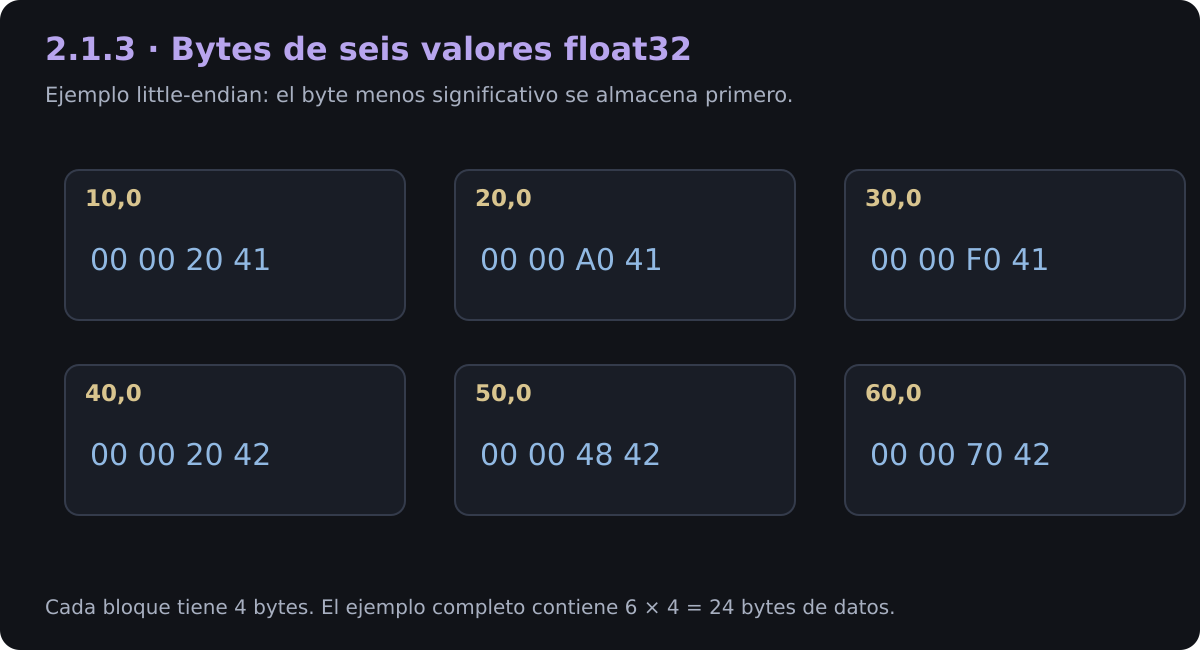

*Fig. 1.6. Representación little-endian de seis valores float32.*

#### Paso 2: reconocer el orden de bytes

En little-endian, el byte menos significativo aparece primero. Los bytes `00 00 20 41` corresponden al patrón de bits que suele escribirse como `0x41200000`.

No se invierten los bits dentro de cada byte. El ejemplo informa `sys.byteorder`; su decodificación con `struct.unpack("=f", ...)` utiliza el orden nativo del host. No todas las plataformas deben suponerse little-endian.

#### Paso 3: decodificar IEEE 754

Un `float32` tiene un bit de signo, ocho de exponente y 23 de fracción. Para un número **normal**, con exponente almacenado entre 1 y 254:

$$x=(-1)^s(1+f)2^{E-127}.$$

Los exponentes 0 y 255 se utilizan para subnormales/ceros y para infinitos/NaN, respectivamente. Por eso la fórmula anterior no se aplica a todos los patrones de bits.

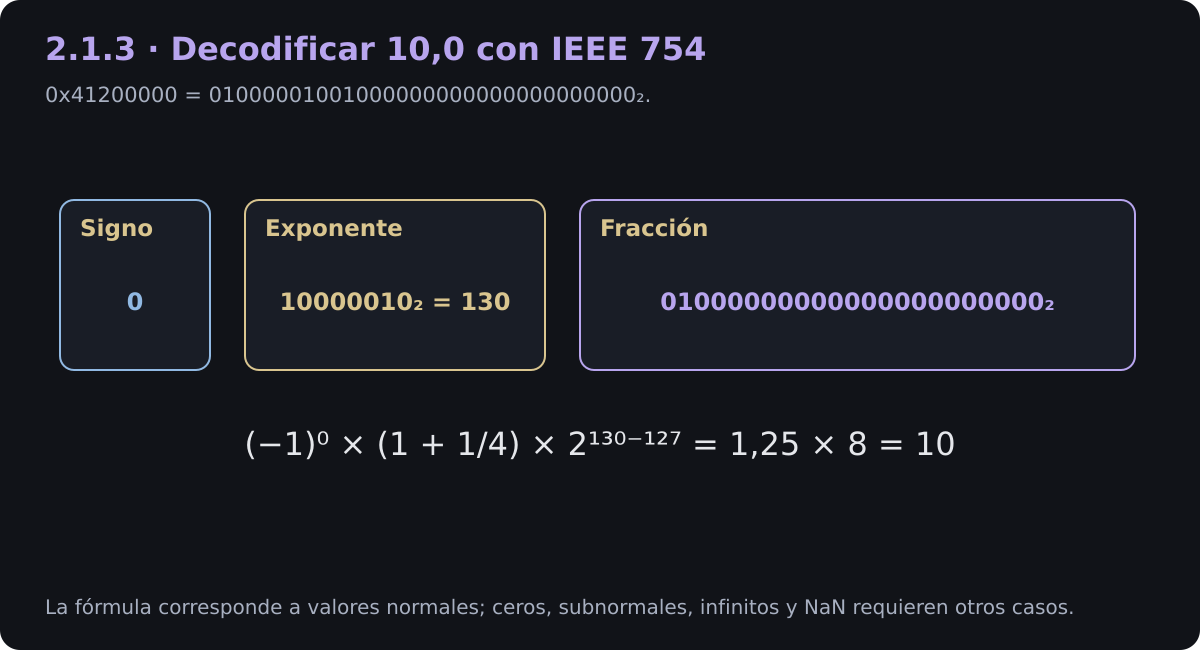

*Fig. 1.7. Decodificación del valor normal 10.0 mediante IEEE 754.*

Para `0x41200000`, el signo es $s=0$, el exponente es $E=130$ y la fracción es $f=1/4$:

$$x=(1+1/4)\,2^{130-127}=1.25\times8=10.$$

El exponente aporta la escala; la fracción aporta la parte adicional del significando.

#### Paso 4: reconstruir la matriz 2 × 3

La primera fila lee los offsets de elemento `0,1,2`; la segunda, `3,4,5`. Los strides `(3,1)` explican esta organización. Los bytes no contienen separadores de fila: esa interpretación pertenece al descriptor del tensor.

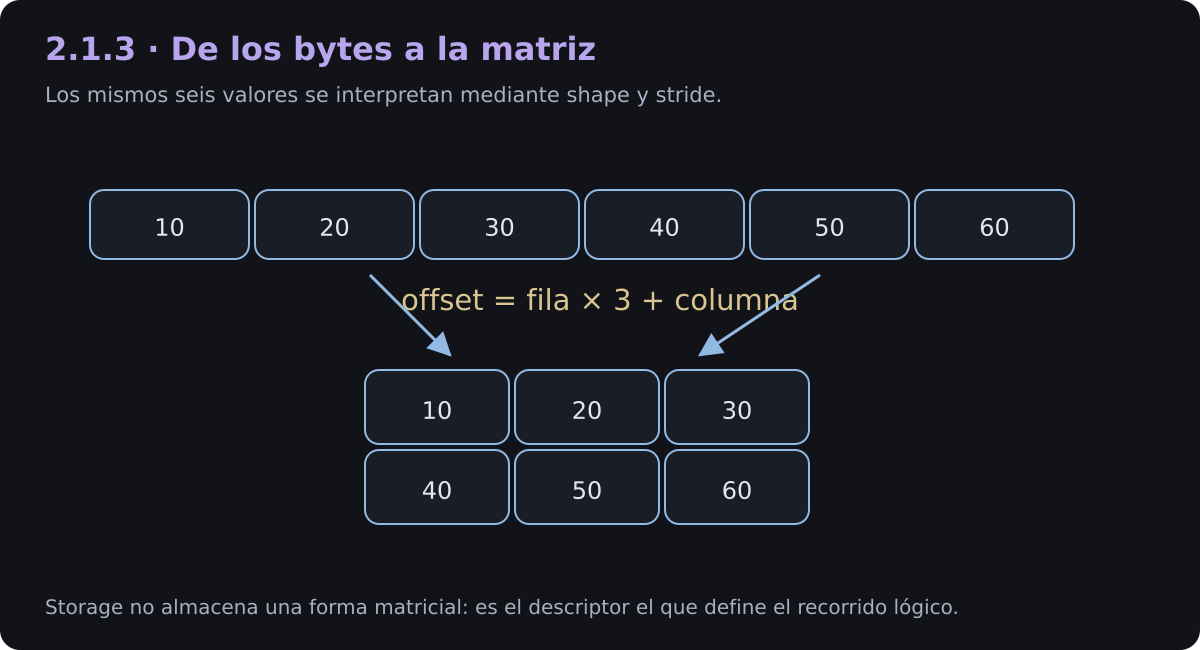

*Fig. 1.8. Reconstrucción de una matriz usando shape y stride.*

## 2.2. Creación e inicialización de tensores

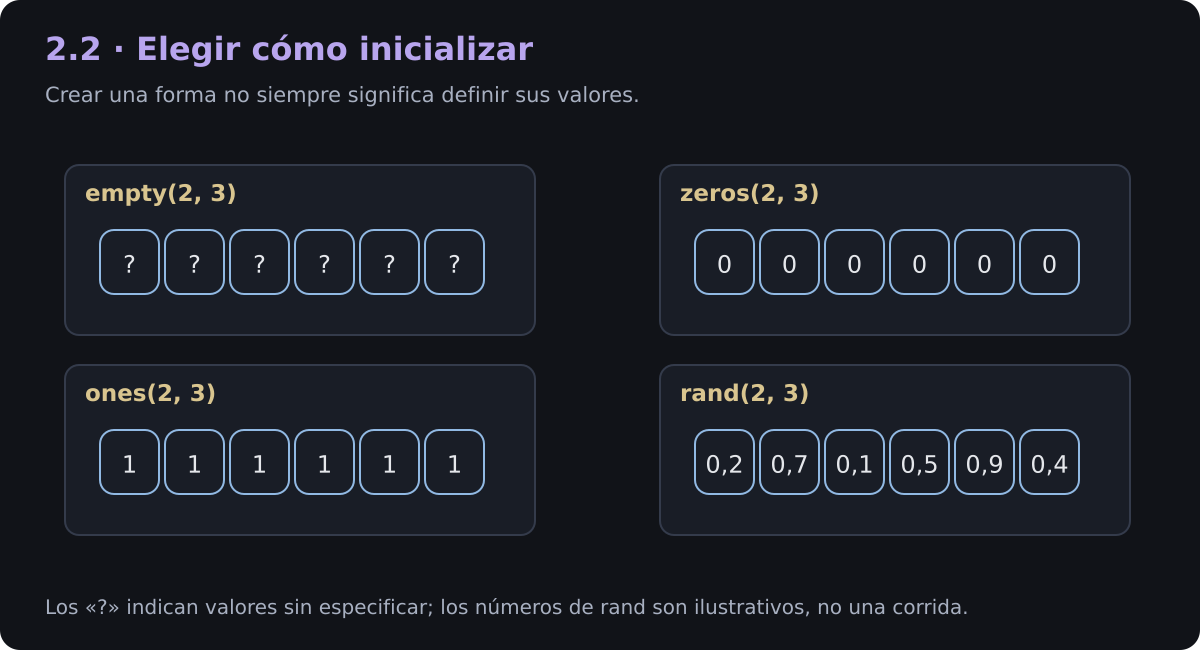

*Fig. 1.9. Inicialización vacía, constante o aleatoria.*

Las funciones de creación determinan la forma y cómo se inicializan los datos:

| Función | Inicialización | Nota |
| :--- | :--- | :--- |
| `torch.empty` | Valores no especificados | Escribir antes de utilizarlos |
| `torch.zeros` | Ceros | Puede fijarse `dtype` y `device` |
| `torch.ones` | Unos | Puede fijarse `dtype` y `device` |
| `torch.rand` | Uniforme en `[0,1)` | Para dtypes flotantes compatibles |
| `torch.randn` | Normal estándar | Media 0 y desviación estándar 1 |

Fijar una semilla ayuda a repetir una secuencia en el mismo entorno. No garantiza identidad entre cualquier dispositivo, versión y algoritmo.

In [3]:
# Importar las fábricas de tensores.
import torch

# Fijar la semilla de esta demostración en el entorno actual.
torch.manual_seed(42)
# Reservar datos sin especificar sus valores iniciales.
x_empty = torch.empty(2, 3)
# Inspeccionar la forma sin leer los valores no inicializados.
print("empty: forma", tuple(x_empty.shape), "— valores aún no especificados")
# Inicializar esos datos antes de utilizarlos.
x_empty.fill_(7.0)
# Mostrar el resultado ya inicializado.
print("empty después de fill_(7):", x_empty)
# Crear y mostrar un tensor de ceros.
x_zeros = torch.zeros(2, 3)
print("zeros:", x_zeros)
# Crear y mostrar un tensor de unos.
x_ones = torch.ones(3, 3)
print("ones:", x_ones)
# Crear números uniformes en el intervalo [0, 1).
x_rand = torch.rand(2, 3)
# Mostrar una salida de la semilla y el entorno utilizados.
print("rand:", x_rand)


empty: forma (2, 3) — valores aún no especificados
empty después de fill_(7): tensor([[7., 7., 7.],
        [7., 7., 7.]])
zeros: tensor([[0., 0., 0.],
        [0., 0., 0.]])
ones: tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
rand: tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009]])


## 2.3. Creación basada en otros tensores (`*_like`)

`zeros_like`, `ones_like` y `empty_like` usan por defecto la forma, el dtype, el layout y el dispositivo del tensor de referencia. La conservación de formato sigue las reglas de `memory_format=torch.preserve_format`; no debe confundirse con copiar sus valores o todos sus strides.

Son tensores nuevos: **no comparten automáticamente el almacenamiento ni heredan `requires_grad=True`**. Los argumentos explícitos permiten cambiar los valores por defecto.

In [4]:
# Importar las fábricas basadas en otros tensores.
import torch

# Crear una referencia con dtype explícito y seguimiento de gradientes habilitado.
origen = torch.randn(3, 4, dtype=torch.float64, device="cpu", requires_grad=True)
# Crear datos nuevos de ceros con los atributos por defecto de la referencia.
ceros_copia = torch.zeros_like(origen)
# Mostrar los atributos heredados.
print("Referencia:", tuple(origen.shape), origen.dtype, origen.device)
print("zeros_like:", tuple(ceros_copia.shape), ceros_copia.dtype, ceros_copia.device)
# Comprobar que requires_grad no se hereda por defecto.
print("requires_grad:", origen.requires_grad, "→", ceros_copia.requires_grad)
# Comprobar que ambos tensores no vacíos tienen datos independientes.
print("Almacenamientos diferentes:", origen.untyped_storage().data_ptr() != ceros_copia.untyped_storage().data_ptr())


Referencia: (3, 4) torch.float64 cpu
zeros_like: (3, 4) torch.float64 cpu
requires_grad: True → False
Almacenamientos diferentes: True


## 2.4. Modificar la geometría y distinguir vistas de copias

Una vista reutiliza los datos y crea un descriptor con una interpretación diferente. No copia el búfer numérico, pero sí tiene un costo de gestión de metadatos. Ese costo puede depender de la cantidad de ejes: **zero-copy no significa tiempo ni memoria total exactamente cero**.

`transpose` y `unsqueeze` son ejemplos de vistas. `reshape` puede devolver una vista o copiar, según la compatibilidad de la forma con los strides.

### 2.4.1. `view()` frente a `reshape()`

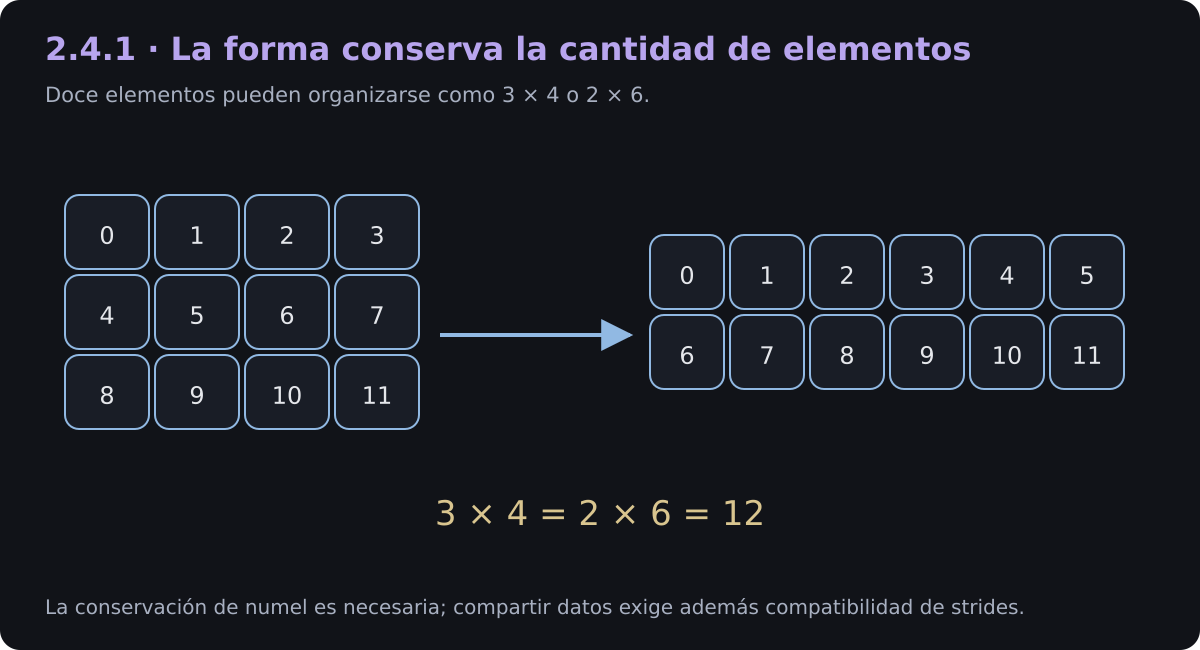

*Fig. 1.10. Cambiar la forma requiere conservar la cantidad de elementos.*

* **`view(*shape)`** devuelve una vista si la nueva forma es compatible con el tamaño y los strides. Ser contiguo es una condición suficiente para muchos cambios de forma, **pero no es un requisito universal**.
* **`reshape(*shape)`** devuelve una vista cuando es posible y copia cuando hace falta. No se debe escribir código que dependa de que siempre ocurra una de esas dos opciones.

Para fusionar un tramo de dimensiones, la condición relevante de compatibilidad incluye:

$$\operatorname{stride}[i]=\operatorname{stride}[i+1]\operatorname{size}[i+1].$$

El número de elementos debe conservarse. `view` también tiene una sobrecarga para reinterpretar el dtype; aquí estudiamos únicamente el cambio de forma.

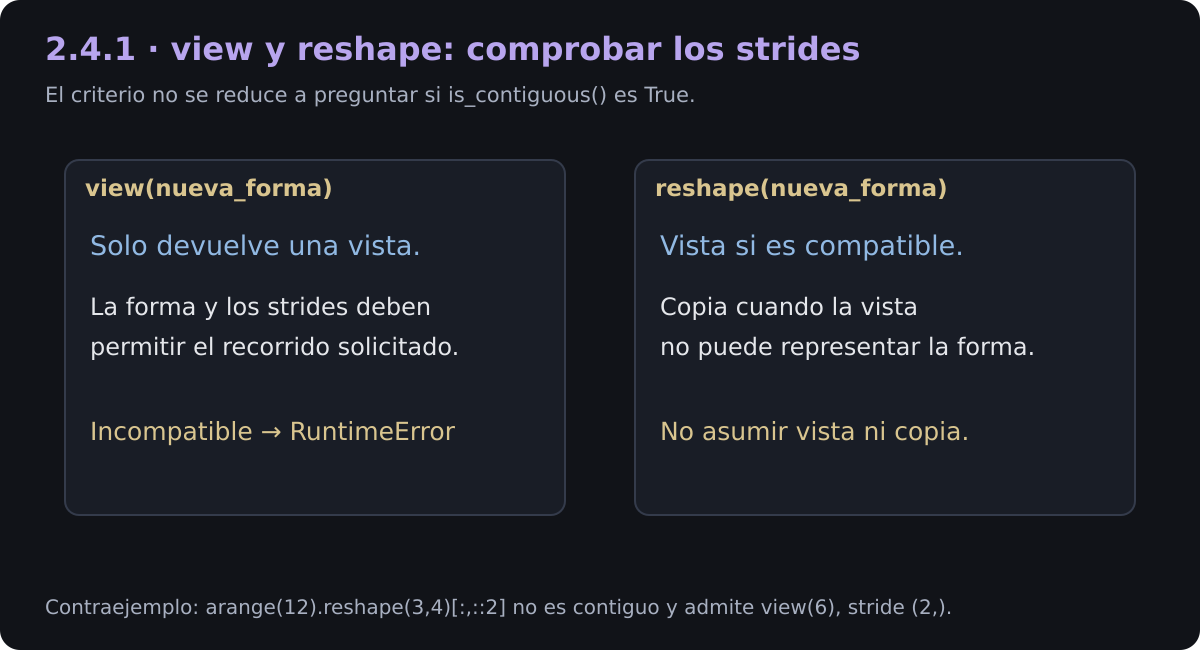

*Fig. 1.11. view exige compatibilidad de strides; reshape puede copiar.*

In [5]:
# Importar PyTorch para inspeccionar vistas y copias.
import torch

def inspeccionar_tensor(nombre, tensor):
    """Muestra metadatos y offsets de una matriz densa en CPU.

    Args:
        nombre: Etiqueta de la demostración.
        tensor: Tensor bidimensional con layout torch.strided y dispositivo CPU.

    Returns:
        None. Imprime valores, strides, offset y recorrido lógico del ejemplo.

    Raises:
        ValueError: Si la entrada no es una matriz densa strided en CPU.
    """
    # Delimitar el ejemplo al formato que se inspecciona.
    if tensor.ndim != 2 or tensor.layout != torch.strided or tensor.device.type != "cpu":
        raise ValueError("Se requiere una matriz densa strided en CPU.")
    # Calcular los offsets incluyendo el comienzo de la vista.
    offsets = [tensor.storage_offset() + r * tensor.stride(0) + c * tensor.stride(1)
               for r in range(tensor.shape[0]) for c in range(tensor.shape[1])]
    # Mostrar los valores y sus propiedades.
    print(f"\n{nombre}\n{tensor}")
    print("shape:", tuple(tensor.shape), "| stride:", tensor.stride(), "| offset:", tensor.storage_offset())
    print("Contiguo estándar:", tensor.is_contiguous(), "| offsets:", offsets)
    print("Base del almacenamiento:", hex(tensor.untyped_storage().data_ptr()))

# Crear la matriz contigua de referencia.
x = torch.arange(12).reshape(3, 4)
# Mostrar su recorrido estándar.
inspeccionar_tensor("Original", x)
# Crear una vista transpuesta sin copiar los datos.
xt = x.t()
# Mostrar el nuevo recorrido lógico.
inspeccionar_tensor("Transpuesta", xt)
# Comprobar el fallo de este aplanado concreto.
try:
    xt.view(12)
except RuntimeError:
    print("xt.view(12): forma incompatible con los strides; error esperado.")
# Obtener una copia contigua de la transpuesta.
x_contiguo = xt.contiguous()
# Mostrar la reorganización de los datos.
inspeccionar_tensor("Transpuesta contigua", x_contiguo)
# Aplanar conservando el orden lógico de la transpuesta.
x_reshape = xt.reshape(12)
print("xt.reshape(12):", x_reshape.tolist())
# Crear una vista no contigua con recorrido compatible con un stride 1D.
saltado = x[:, ::2]
# Mostrar la forma y el stride de esa vista.
inspeccionar_tensor("Vista con salto de dos elementos", saltado)
# Demostrar que la falta de contigüidad no impide cualquier view.
print("saltado.view(6):", saltado.view(6).tolist(), "| stride:", saltado.view(6).stride())



Original
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
shape: (3, 4) | stride: (4, 1) | offset: 0
Contiguo estándar: True | offsets: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Base del almacenamiento: 0x… (varía por ejecución)

Transpuesta
tensor([[ 0,  4,  8],
        [ 1,  5,  9],
        [ 2,  6, 10],
        [ 3,  7, 11]])
shape: (4, 3) | stride: (1, 4) | offset: 0
Contiguo estándar: False | offsets: [0, 4, 8, 1, 5, 9, 2, 6, 10, 3, 7, 11]
Base del almacenamiento: 0x… (varía por ejecución)
xt.view(12): forma incompatible con los strides; error esperado.

Transpuesta contigua
tensor([[ 0,  4,  8],
        [ 1,  5,  9],
        [ 2,  6, 10],
        [ 3,  7, 11]])
shape: (4, 3) | stride: (3, 1) | offset: 0
Contiguo estándar: True | offsets: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Base del almacenamiento: 0x… (varía por ejecución)
xt.reshape(12): [0, 4, 8, 1, 5, 9, 2, 6, 10, 3, 7, 11]

Vista con salto de dos elementos
tensor([[ 0,  2],
        [ 4,  6],
   

#### 2.4.1.1. ¿Qué significa «contiguo»?

En el formato contiguo estándar, los elementos de una matriz no degenerada se recorren por filas mediante strides `(columnas,1)`. Los ejes de tamaño 1 y los tensores vacíos introducen matices; además existe contigüidad relativa a otros formatos, como `channels_last`.

Que una vista no sea contigua no implica que su bloque de almacenamiento esté fragmentado. Describe la relación entre su orden lógico y sus strides.

##### Paso 1: tensor original

Con `x = torch.arange(12).reshape(3,4)`:

$$x=\begin{pmatrix}0&1&2&3\\4&5&6&7\\8&9&10&11\end{pmatrix}.$$

Su forma es `(3,4)`, sus strides son `(4,1)` y su offset inicial es 0. El almacenamiento contiene los valores de 0 a 11 en ese orden.

El recorrido por filas visita offsets `0,1,2,3,4,5,6,7,8,9,10,11`. En este ejemplo, `x.is_contiguous()` devuelve `True`. La contigüidad depende de los metadatos, no de que los valores sean números consecutivos.

##### Paso 2: transposición `xt = x.t()`

La vista tiene forma `(4,3)` y strides `(1,4)`:

$$x^\top=\begin{pmatrix}0&4&8\\1&5&9\\2&6&10\\3&7&11\end{pmatrix}.$$

Comparte el almacenamiento original. Su recorrido lógico por filas visita `0,4,8,1,5,9,2,6,10,3,7,11`, por lo que no es contiguo en el formato estándar. No se ha fragmentado ni reordenado el bloque de datos.

##### Paso 3: ¿por qué falla `xt.view(12)`?

Para conservar el orden lógico de `xt`, una vista 1D tendría que recorrer `0,4,8,1,5,9,...`. Ese recorrido no se puede representar mediante un único stride constante. Por eso **este aplanado concreto** falla.

No toda vista no contigua falla: `x[:, ::2]` tiene forma `(3,2)` y strides `(4,2)`. Admite `view(6)` porque sus offsets `0,2,4,6,8,10` sí se describen con stride 2. El código comprueba ambos casos.

##### Paso 4: `contiguous()` y `reshape()`

* Para `xt`, `contiguous()` crea una copia organizada en su orden lógico, con forma `(4,3)` y strides `(3,1)`. Si el tensor ya era contiguo en el formato solicitado, devuelve el propio tensor.
* `xt.reshape(12)` conserva el orden lógico de la transpuesta y en este caso requiere copiar. El resultado es `[0,4,8,1,5,9,2,6,10,3,7,11]`.

No corresponde resumir `reshape` como un `if is_contiguous()` seguido siempre por copia para el caso falso: también existen vistas no contiguas compatibles.

### 2.4.2. Ejes unitarios: `squeeze` y `unsqueeze`

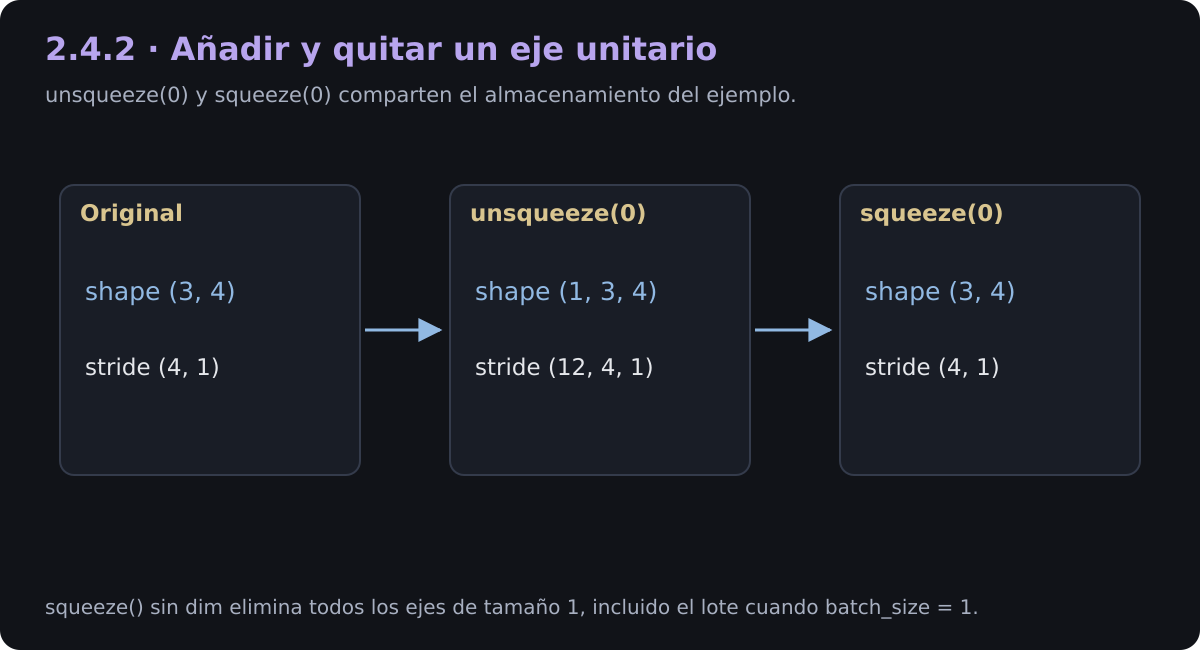

*Fig. 1.12. Inserción y eliminación de un eje unitario.*

`unsqueeze(dim)` devuelve una vista con un eje nuevo de tamaño 1. `squeeze()` elimina todos los ejes unitarios; `squeeze(dim)` solo elimina el eje indicado si su tamaño es 1.

Las operaciones del ejemplo mantienen los datos compartidos. No cambian la cantidad de elementos.

In [6]:
# Importar PyTorch para insertar y eliminar ejes.
import torch

def inspeccionar(nombre, tensor, nota=""):
    """Describe los metadatos de un tensor denso del ejemplo.

    Args:
        nombre: Etiqueta del tensor.
        tensor: Tensor strided no vacío que se desea examinar.
        nota: Aclaración opcional que acompaña la etiqueta.

    Returns:
        None. Imprime forma, strides, offset y direcciones de la vista y del bloque.
    """
    # Mostrar la etiqueta y la aclaración.
    print(f"\n{nombre} {nota}")
    # Mostrar los ejes y las zancadas.
    print("shape:", tuple(tensor.shape), "| stride:", tensor.stride(), "| offset:", tensor.storage_offset())
    # Distinguir el comienzo de la vista de la base del almacenamiento.
    print("data_ptr:", hex(tensor.data_ptr()), "| storage:", hex(tensor.untyped_storage().data_ptr()))

# Crear una matriz de valores conocidos.
original = torch.arange(12).reshape(3, 4)
# Insertar un eje de lote de tamaño 1.
con_batch = original.unsqueeze(0)
# Eliminar específicamente ese eje.
comprimido = con_batch.squeeze(0)
# Inspeccionar las tres interpretaciones.
inspeccionar("Original", original)
inspeccionar("Con lote", con_batch)
inspeccionar("Sin lote unitario", comprimido)
# Comprobar el almacenamiento compartido en este ejemplo no vacío.
print("Base compartida:", original.untyped_storage().data_ptr() == con_batch.untyped_storage().data_ptr() == comprimido.untyped_storage().data_ptr())
# Mostrar el efecto de quitar todos los ejes unitarios frente a elegir el último.
salida = torch.ones(1, 1)
print("squeeze():", tuple(salida.squeeze().shape), "| squeeze(-1):", tuple(salida.squeeze(-1).shape))



Original 
shape: (3, 4) | stride: (4, 1) | offset: 0
data_ptr: 0x… (varía por ejecución) | storage: 0x… (varía por ejecución)

Con lote 
shape: (1, 3, 4) | stride: (12, 4, 1) | offset: 0
data_ptr: 0x… (varía por ejecución) | storage: 0x… (varía por ejecución)

Sin lote unitario 
shape: (3, 4) | stride: (4, 1) | offset: 0
data_ptr: 0x… (varía por ejecución) | storage: 0x… (varía por ejecución)
Base compartida: True
squeeze(): () | squeeze(-1): (1,)


#### 2.4.2.1. Metadatos frente a datos

La forma y los strides cambian en el descriptor de la vista, mientras que el almacenamiento permanece compartido. El ejemplo inspecciona tanto `data_ptr()` como la base del almacenamiento.

En estos tensores no vacíos, la coincidencia de esos punteros respalda la observación. No conviene usar un único puntero como prueba universal de identidad entre objetos, especialmente con tensores vacíos o almacenamiento externo.

##### Paso 1: tensor original

Una matriz de forma `(3,4)` tiene dos ejes y strides estándar `(4,1)`. El offset es `fila*4 + columna`, porque el ejemplo comienza en el offset 0 del almacenamiento.

##### Paso 2: `con_batch = original.unsqueeze(0)`

La forma pasa a `(1,3,4)` y los strides del ejemplo son `(12,4,1)`. El índice del nuevo eje solo puede ser 0, por lo que `batch*12` no cambia ninguna dirección leída. No se duplica el búfer de datos.

##### Paso 3: `comprimido = con_batch.squeeze(0)`

Se elimina únicamente el eje inicial, recuperando la forma `(3,4)`. Esta variante hace explícita la intención.

**Aplicación:** una imagen `(C,H,W)` puede convertirse en un lote `(1,C,H,W)` con `unsqueeze(0)` si el modelo espera ese formato. Algunas capas también aceptan entradas sin lote; depende de su contrato.

**Cuidado con `squeeze()` sin `dim`:** una salida `(1,1)` se convertiría en un escalar y perdería el eje de lote. Para una salida `(B,1)`, suele ser más preciso usar `squeeze(-1)` y conservar `(B,)`, incluso cuando `B=1`.

## 2.5. Operaciones y broadcasting

PyTorch dispone de operadores con diferentes implementaciones según el dispositivo, el layout, el dtype y otros estados. El dispatcher participa en esa selección.

No todos los operadores están disponibles para cualquier combinación de dtype y backend. La existencia de aceleración no implica que una operación sea siempre más rápida en GPU.

### 2.5.1. El mecanismo de broadcasting

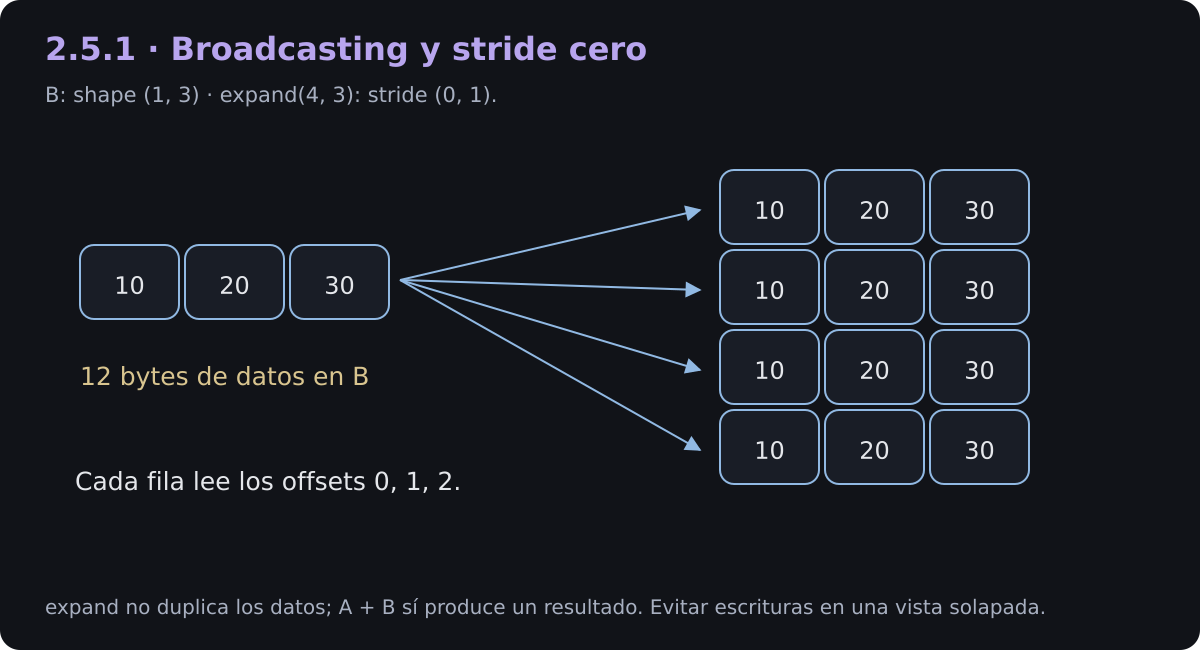

*Fig. 1.13. Una vista expandida reutiliza datos mediante stride cero.*

Para combinar tensores elemento a elemento, se alinean sus ejes **de derecha a izquierda**. Dos tamaños son compatibles si son iguales o si uno es 1; los ejes ausentes se consideran de tamaño 1.

Por ejemplo, `(4,3,5)` y `(3,1)` pueden producir forma `(4,3,5)`. Los escalares 0D también participan en las operaciones compatibles.

La expansión lógica no exige materializar copias de las entradas. Sin embargo, un resultado fuera de sitio como `A + B` necesita almacenamiento para sus valores.

In [7]:
# Importar PyTorch para observar una expansión.
import torch

def inspeccionar(nombre, tensor, nota=""):
    """Distingue el tamaño lógico del tamaño del almacenamiento compartido.

    Args:
        nombre: Etiqueta del tensor.
        tensor: Tensor denso strided en CPU para esta demostración.
        nota: Explicación opcional.

    Returns:
        None. Imprime los valores, los strides y ambas medidas de tamaño.
    """
    # Mostrar los valores y la forma lógica.
    print(f"\n{nombre} {nota}\n{tensor}")
    print("shape:", tuple(tensor.shape), "| stride:", tensor.stride())
    # Medir los elementos lógicos, que pueden reutilizar las mismas posiciones.
    print("Bytes lógicos:", tensor.numel() * tensor.element_size())
    # Medir el bloque de datos real que respalda la vista.
    print("Bytes del almacenamiento:", tensor.untyped_storage().nbytes())

# Crear una matriz y una fila float32.
A = torch.ones(4, 3, dtype=torch.float32)
B = torch.tensor([[10.0, 20.0, 30.0]], dtype=torch.float32)
# Crear una vista que reutiliza la única fila mediante stride cero.
B_virtual = B.expand(4, 3)
# Calcular un resultado fuera de sitio con broadcasting.
resultado = A + B
# Inspeccionar los tres papeles de la demostración.
inspeccionar("B original", B)
inspeccionar("B expandido", B_virtual)
inspeccionar("A + B", resultado)
# Verificar que expand no ha creado otro bloque de datos.
print("B y expand comparten almacenamiento:", B.untyped_storage().data_ptr() == B_virtual.untyped_storage().data_ptr())



B original 
tensor([[10., 20., 30.]])
shape: (1, 3) | stride: (3, 1)
Bytes lógicos: 12
Bytes del almacenamiento: 12

B expandido 
tensor([[10., 20., 30.],
        [10., 20., 30.],
        [10., 20., 30.],
        [10., 20., 30.]])
shape: (4, 3) | stride: (0, 1)
Bytes lógicos: 48
Bytes del almacenamiento: 12

A + B 
tensor([[11., 21., 31.],
        [11., 21., 31.],
        [11., 21., 31.],
        [11., 21., 31.]])
shape: (4, 3) | stride: (3, 1)
Bytes lógicos: 48
Bytes del almacenamiento: 48
B y expand comparten almacenamiento: True


#### 2.5.1.1. ¿Qué se expande?

Con `A` de forma `(4,3)` y `B` de forma `(1,3)`, la suma utiliza la única fila de `B` para cada fila de `A`. `B.expand(4,3)` permite observar una vista explícita de esa reutilización.

#### 2.5.1.2. Compatibilidad de derecha a izquierda

El último eje compara `3` con `3`: coincide. El anterior compara `4` con `1`: puede expandirse el tamaño 1. El resultado tiene forma `(4,3)`.

Un tamaño 2 no puede expandirse directamente a 4 por broadcasting: debe ser 1 o coincidir con el otro tamaño.

#### 2.5.1.3. El stride cero de `expand`

La fila `B = [[10,20,30]]`, creada como `float32`, tiene strides `(3,1)` y 12 bytes de datos. La vista expandida `(4,3)` tiene strides `(0,1)`.

Sus 12 posiciones lógicas reutilizan los tres elementos originales. El tamaño lógico es 48 bytes, mientras que el almacenamiento compartido sigue teniendo 12 bytes. Esto no incluye el costo de los objetos y metadatos.

#### 2.5.1.4. Direccionamiento con stride cero

En esta vista, cuyo offset inicial es 0:

$$o=\mathrm{fila}\times0+\mathrm{columna}\times1.$$

Las posiciones `[0,0]`, `[1,0]`, `[2,0]` y `[3,0]` leen el mismo elemento. Cada fila vuelve a visitar offsets `0,1,2`.

**No modificar indiscriminadamente una vista expandida:** distintas posiciones lógicas pueden aliasar el mismo elemento. Para obtener datos independientes antes de escribir, puede usarse `clone()`.

#### 2.5.1.5. La suma `resultado = A + B`

Con `A` llena de unos y `B = [[10,20,30]]`:

$$A+B=\begin{pmatrix}11&21&31\\11&21&31\\11&21&31\\11&21&31\end{pmatrix}.$$

La expresión fuera de sitio crea un resultado con 12 elementos `float32`: 48 bytes lógicos, además de los costos del asignador y los metadatos. No necesita copiar previamente las cuatro filas de `B`. Otras variantes con `out=` o in-place tienen contratos diferentes.

## 2.6. Álgebra lineal y transposición

La multiplicación matricial contrae una dimensión mediante sumas de productos. La transposición reordena ejes; no debe confundirse con redimensionar ni con multiplicar elemento a elemento.

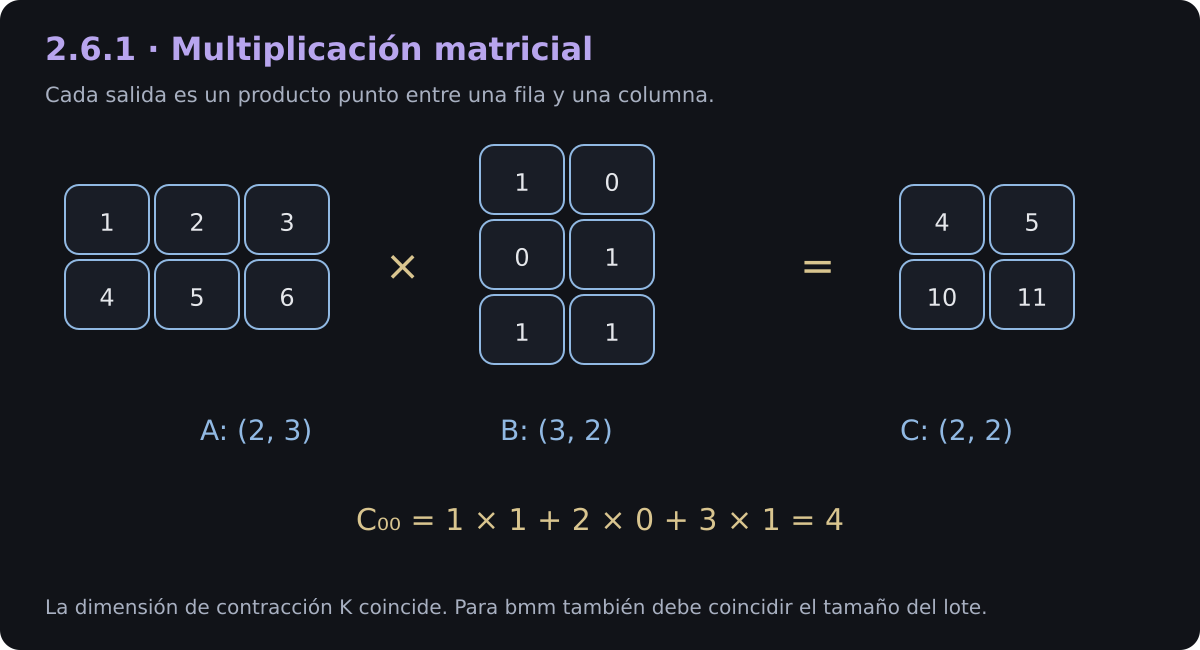

*Fig. 1.14. Un ejemplo numérico de multiplicación matricial.*

### 2.6.1. Productos matriciales en PyTorch

* `torch.dot`: dos vectores 1D de la misma longitud; devuelve un escalar.
* `torch.mm`: dos matrices 2D con dimensión interna compatible; no aplica broadcasting.
* `torch.bmm`: dos tensores 3D, con el mismo tamaño de lote y dimensión interna compatible; no aplica broadcasting de lote.
* `torch.matmul` / `@`: maneja vectores y matrices según sus reglas de rango, y permite broadcasting en las dimensiones de lote. No acepta operandos escalares 0D.

In [8]:
# Importar las operaciones matriciales.
import torch

def inspeccionar(nombre, tensor, nota=""):
    """Muestra la forma de un resultado matricial y su tamaño lógico.

    Args:
        nombre: Etiqueta del ejemplo.
        tensor: Tensor denso que se desea inspeccionar.
        nota: Descripción opcional de sus dimensiones.

    Returns:
        None. Imprime valores, forma, strides y bytes lógicos.
    """
    # Mostrar los resultados numéricos de ejemplos pequeños.
    print(f"\n{nombre} {nota}\n{tensor}")
    # Informar la forma y el recorrido de la salida.
    print("shape:", tuple(tensor.shape), "| stride:", tensor.stride())
    # Contabilizar los elementos lógicos sin incluir el costo del asignador.
    print("Bytes lógicos:", tensor.numel() * tensor.element_size())

# Elegir valores que permitan verificar los productos a mano.
A = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
B = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
# Calcular el producto 2D de filas por columnas.
C = A @ B
# Mostrar la salida exacta del ejemplo.
inspeccionar("A @ B", C)
# Crear dos lotes compatibles para bmm.
lote_A = torch.arange(60, dtype=torch.float32).reshape(10, 2, 3)
lote_B = torch.ones(10, 3, 5)
# Calcular diez productos independientes.
lote_C = torch.bmm(lote_A, lote_B)
# Mostrar los metadatos sin imprimir todo el lote.
print("bmm:", tuple(lote_A.shape), "×", tuple(lote_B.shape), "→", tuple(lote_C.shape))
print("Strides de lote_A:", lote_A.stride(), "| primer resultado:", lote_C[0])
# Mostrar broadcasting de lote en matmul, que bmm no ofrece.
matrices = torch.ones(2, 1, 3, 4)
pesos = torch.ones(5, 4, 6)
print("matmul con broadcasting:", tuple((matrices @ pesos).shape))



A @ B 
tensor([[ 4.,  5.],
        [10., 11.]])
shape: (2, 2) | stride: (2, 1)
Bytes lógicos: 16
bmm: (10, 2, 3) × (10, 3, 5) → (10, 2, 5)
Strides de lote_A: (6, 3, 1) | primer resultado: tensor([[ 3.,  3.,  3.,  3.,  3.],
        [12., 12., 12., 12., 12.]])
matmul con broadcasting: (2, 5, 3, 6)


#### 2.6.1.1. Multiplicación 2D (`A @ B` o `torch.mm`)

Cada entrada de salida combina una fila de `A` con una columna de `B`. El operador `*`, en cambio, multiplica elemento a elemento con las reglas de broadcasting aplicables.

##### 1. La dimensión de contracción

$$A\in\mathbb R^{M\times K},\quad B\in\mathbb R^{K\times N}\quad\Longrightarrow\quad C\in\mathbb R^{M\times N}.$$

$$C_{ij}=\sum_{k=0}^{K-1}A_{ik}B_{kj}.$$

En el ejemplo de forma `(2,3) @ (3,4)`, la salida tiene forma `(2,4)`. La expresión `C = A @ B` produce un resultado; no es una vista de las entradas. Las variantes con `out=` pueden reutilizar un tensor de destino compatible.

El producto es bilineal respecto a sus dos entradas. Una transformación afín de una entrada fija requeriría además un sesgo, por ejemplo `X @ W + b`.

#### 2.6.1.2. Multiplicación por lotes (`torch.bmm`)

$$[B,M,K]\times[B,K,N]\longrightarrow[B,M,N].$$

El ejemplo `(10,2,3)` por `(10,3,5)` produce `(10,2,5)`: diez productos independientes. La ejecución concreta y su paralelismo dependen del backend; no se deduce una distribución fija de hilos o kernels únicamente de esa forma.

##### 1. Strides de lote

Para `lote_A` contiguo de forma `(10,2,3)`, los strides son `(6,3,1)`: avanzar un lote desplaza seis elementos; avanzar una fila, tres; avanzar una columna, uno.

Estos valores describen ese tensor contiguo. Otro tensor con la misma forma puede tener strides diferentes. La fórmula general sigue incluyendo su `storage_offset`.

#### 2.6.1.3. Tabla comparativa

| Operación | Entradas | Salida | Broadcasting |
| :--- | :--- | :--- | :--- |
| `dot` | `(K,)`, `(K,)` | Escalar | No |
| `mm` | `(M,K)`, `(K,N)` | `(M,N)` | No |
| `bmm` | `(B,M,K)`, `(B,K,N)` | `(B,M,N)` | No |
| `matmul` | Vectores o matrices compatibles | Según rangos | En ejes de lote |

**Idea para recordar:** antes de elegir una operación, verificá qué ejes representan lote y cuáles participan en la contracción.

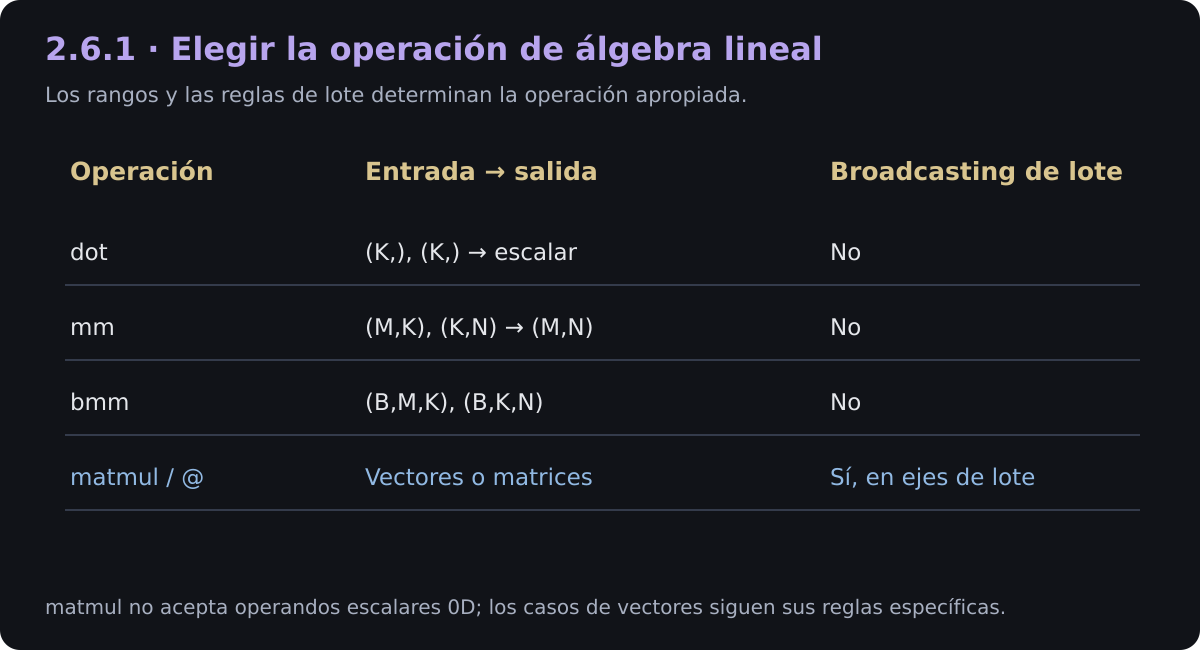

*Fig. 1.15. Comparación de rangos y broadcasting de las operaciones.*